In [3]:

import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import pickle #save encoders, scaler  
import warnings
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import xgboost as xgb


sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ All libraries imported successfully!")


✓ All libraries imported successfully!


## 2. Feature Extraction Functions 

Extract 190 features from audio files:
- 40 MFCC coefficients
- 12 Chroma features
- 128 Mel Spectrogram features
- Spectral Centroid, Bandwidth, Contrast (7)
- Zero-Crossing Rate, RMS Energy


In [8]:


def extract_mfcc(y, sr, n_mfcc=40):
    """Extract MFCC (Mel-Frequency Cepstral Coefficients) features."""
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    return np.mean(mfccs.T, axis=0)

def extract_chroma(y, sr):
    """Extract Chroma features (pitch class profile)."""
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    return np.mean(chroma.T, axis=0)

def extract_mel_spectrogram(y, sr, n_mels=128):
    """Extract Mel Spectrogram and flatten it."""
    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels)
    mel_mean = np.mean(mel_spec.T, axis=0)
    return mel_mean

def extract_spectral_centroid(y, sr):
    """Extract Spectral Centroid (brightness of sound)."""
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    return np.mean(centroid)

def extract_spectral_bandwidth(y, sr):
    """Extract Spectral Bandwidth (spread of spectrum)."""
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    return np.mean(bandwidth)

def extract_spectral_contrast(y, sr):
    """Extract Spectral Contrast features."""
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    return np.mean(contrast.T, axis=0)

def extract_zero_crossing_rate(y):
    """Extract Zero-Crossing Rate (ZCR)."""
    zcr = librosa.feature.zero_crossing_rate(y)
    return np.mean(zcr)

def extract_rms_energy(y):
    """Extract RMS (Root Mean Square) Energy."""
    rms = librosa.feature.rms(y=y)
    return np.mean(rms)

def extract_all_features(audio_path, sr=22050):
    """Extract all features from an audio file."""
    try:
       
        y, sample_rate = librosa.load(audio_path, sr=sr)
        
        
        features = {}
        
       
        mfcc = extract_mfcc(y, sample_rate, n_mfcc=40)
        for i, val in enumerate(mfcc, 1):
            features[f'mfcc_{i}'] = val
        
        
        chroma = extract_chroma(y, sample_rate)
        for i, val in enumerate(chroma, 1):
            features[f'chroma_{i}'] = val
        
       
        mel_spec = extract_mel_spectrogram(y, sample_rate, n_mels=128)
        for i, val in enumerate(mel_spec, 1):
            features[f'mel_spec_{i}'] = val
        
       
        features['spectral_centroid'] = extract_spectral_centroid(y, sample_rate)
        features['spectral_bandwidth'] = extract_spectral_bandwidth(y, sample_rate)
        
        
        contrast = extract_spectral_contrast(y, sample_rate)
        for i, val in enumerate(contrast, 1):
            features[f'spectral_contrast_{i}'] = val
        
        
        features['zcr'] = extract_zero_crossing_rate(y)
        features['rms'] = extract_rms_energy(y)
        
        return features
    
    except Exception as e:
        print(f"Error processing {audio_path}: {str(e)}")
        return None

def parse_emotion_from_filename(filename):
    """Parse emotion label from RAVDESS filename."""
    emotion_map = {
        '01': 'neutral', '02': 'calm', '03': 'happy', '04': 'sad',
        '05': 'angry', '06': 'fearful', '07': 'disgust', '08': 'surprised'
    }
    
    try:
        parts = Path(filename).stem.split('-')
        if len(parts) >= 3:
            emotion_code = parts[2]
            return emotion_map.get(emotion_code, 'unknown')
    except:
        pass
    
    return 'unknown'

print("✓ Feature extraction functions defined!")


✓ Feature extraction functions defined!


### Extract Features from All Audio Files


In [5]:

data_dir = Path("../data/ravdess") 


features_csv = Path("../data/features.csv")

if features_csv.exists():
    print(f"Features file already exists: {features_csv}")
    print("Loading existing features...")
    df_features = pd.read_csv(features_csv)
    print(f"Loaded {len(df_features)} samples")
else:
    print("Extracting features from audio files...")
    print("This may take 10-30 minutes depending on the number of files...")
    
    audio_files = list(data_dir.rglob('*.wav'))
    print(f"Found {len(audio_files)} audio files")
    
    all_features = []
    
    for i, audio_path in enumerate(audio_files, 1):
        if i % 100 == 0:
            print(f"Processed {i}/{len(audio_files)} files...")
        
        features = extract_all_features(str(audio_path))
        
        if features is not None:
            features['file_path'] = str(audio_path)
            features['emotion'] = parse_emotion_from_filename(audio_path.name)
            all_features.append(features)
    
    
    df_features = pd.DataFrame(all_features)
    
    
    feature_cols = [col for col in df_features.columns if col not in ['file_path', 'emotion']]
    df_features = df_features[['file_path', 'emotion'] + sorted(feature_cols)]
    
  
    df_features.to_csv(features_csv, index=False)
    print(f"\n✓ Extracted features from {len(df_features)} files")
    print(f"✓ Features saved to {features_csv}")

print(f"\nDataFrame shape: {df_features.shape}")
print(f"Emotion distribution:")
print(df_features['emotion'].value_counts())


Features file already exists: ..\data\features.csv
Loading existing features...
Loaded 2880 samples

DataFrame shape: (2880, 193)
Emotion distribution:
emotion
calm         384
happy        384
sad          384
angry        384
fearful      384
disgust      384
surprised    384
neutral      192
Name: count, dtype: int64


## 3. Data Preprocessing 


In [ ]:

feature_cols = [col for col in df_features.columns if col not in ['file_path', 'emotion']]
X = df_features[feature_cols].values
y = df_features['emotion'].values


if np.isnan(X).any():
    print("Warning: Found NaN values. Filling with mean...")
    X = pd.DataFrame(X).fillna(pd.DataFrame(X).mean()).values


label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train_scaled.shape}")
print(f"Test set: {X_test_scaled.shape}")
print(f"Number of classes: {len(label_encoder.classes_)}")
print(f"Classes: {label_encoder.classes_}")


X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print(f"\nTrain split: {X_train_split.shape}")
print(f"Validation split: {X_val.shape}")


models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

with open(models_dir / 'label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

with open(models_dir / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)


with open(models_dir / 'feature_names.pkl', 'wb') as f:
    pickle.dump(sorted(feature_cols), f)

print("\n✓ Preprocessing complete!")
print("✓ Preprocessing artifacts saved to ../models/")


Training set: (2304, 191)
Test set: (576, 191)
Number of classes: 8
Classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']

Train split: (1843, 191)
Validation split: (461, 191)

✓ Preprocessing complete!
✓ Preprocessing artifacts saved to ../models/


## 4. Model Training

5 different ML models and select the best one:
- SVM (Support Vector Machine)
- Random Forest
- XGBoost
- Gradient Boosting
- Logistic Regression


In [ ]:


def train_svm(X_train, y_train, X_val, y_val):
    """Train Support Vector Machine classifier."""
    print("Training SVM...")
    model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    f1 = f1_score(y_val, y_pred, average='weighted')
    print(f"SVM Validation F1-score: {f1:.4f}")
    return model, f1

def train_random_forest(X_train, y_train, X_val, y_val, n_estimators=100):
    """Train Random Forest classifier."""
    print("Training Random Forest...")
    model = RandomForestClassifier(
        n_estimators=n_estimators, max_depth=20,
        min_samples_split=5, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    f1 = f1_score(y_val, y_pred, average='weighted')
    print(f"Random Forest Validation F1-score: {f1:.4f}")
    return model, f1

def train_xgboost(X_train, y_train, X_val, y_val, n_estimators=100):
    """Train XGBoost classifier."""
    print("Training XGBoost...")
    model = xgb.XGBClassifier(
        n_estimators=n_estimators, max_depth=6,
        learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='mlogloss'
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    f1 = f1_score(y_val, y_pred, average='weighted')
    print(f"XGBoost Validation F1-score: {f1:.4f}")
    return model, f1

def train_gradient_boosting(X_train, y_train, X_val, y_val, n_estimators=100):
    """Train Gradient Boosting classifier."""
    print("Training Gradient Boosting...")
    model = GradientBoostingClassifier(
        n_estimators=n_estimators, max_depth=5,
        learning_rate=0.1, random_state=42
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    f1 = f1_score(y_val, y_pred, average='weighted')
    print(f"Gradient Boosting Validation F1-score: {f1:.4f}")
    return model, f1

def train_logistic_regression(X_train, y_train, X_val, y_val):
    """Train Logistic Regression classifier (baseline)."""
    print("Training Logistic Regression...")
    model = LogisticRegression(
        max_iter=1000, random_state=42,
        multi_class='multinomial', solver='lbfgs'
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    f1 = f1_score(y_val, y_pred, average='weighted')
    print(f"Logistic Regression Validation F1-score: {f1:.4f}")
    return model, f1

print("✓ Training functions defined!")


✓ Training functions defined!


### Train All Models


In [ ]:

print("="*60)
print("TRAINING ALL MODELS")
print("="*60)

results = {}


results['SVM'] = train_svm(X_train_split, y_train_split, X_val, y_val)
results['RandomForest'] = train_random_forest(X_train_split, y_train_split, X_val, y_val)
results['XGBoost'] = train_xgboost(X_train_split, y_train_split, X_val, y_val)
results['GradientBoosting'] = train_gradient_boosting(X_train_split, y_train_split, X_val, y_val)
results['LogisticRegression'] = train_logistic_regression(X_train_split, y_train_split, X_val, y_val)


print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)

best_name = None
best_model = None
best_f1 = -1

for name, (model, f1) in results.items():
    print(f"{name:20s}: F1-score = {f1:.4f}")
    if f1 > best_f1:
        best_f1 = f1
        best_model = model
        best_name = name

print("="*60)
print(f"Best Model: {best_name} (F1-score: {best_f1:.4f})")
print("="*60)


with open(models_dir / 'saved_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

print(f"\n✓ Best model saved to {models_dir / 'saved_model.pkl'}")


TRAINING ALL MODELS
Training SVM...
SVM Validation F1-score: 0.5934
Training Random Forest...
Random Forest Validation F1-score: 0.8371
Training XGBoost...
XGBoost Validation F1-score: 0.8615
Training Gradient Boosting...
Gradient Boosting Validation F1-score: 0.8436
Training Logistic Regression...
Logistic Regression Validation F1-score: 0.6369

MODEL COMPARISON
SVM                 : F1-score = 0.5934
RandomForest        : F1-score = 0.8371
XGBoost             : F1-score = 0.8615
GradientBoosting    : F1-score = 0.8436
LogisticRegression  : F1-score = 0.6369
Best Model: XGBoost (F1-score: 0.8615)

✓ Best model saved to ..\models\saved_model.pkl


## 5. Model Evaluation 



In [ ]:

y_pred_test = best_model.predict(X_test_scaled)


accuracy = accuracy_score(y_test, y_pred_test)
precision = precision_score(y_test, y_pred_test, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred_test, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_test, average='weighted', zero_division=0)

print("="*60)
print("EVALUATION METRICS (Test Set)")
print("="*60)
print(f"Accuracy:           {accuracy:.4f}")
print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted):    {recall:.4f}")
print(f"F1-Score (weighted):  {f1:.4f}")
print("="*60)


print("\nCLASSIFICATION REPORT")
print("="*60)
class_names = label_encoder.classes_
print(classification_report(y_test, y_pred_test, target_names=class_names, zero_division=0))
print("="*60)


EVALUATION METRICS (Test Set)
Accuracy:           0.8264
Precision (weighted): 0.8262
Recall (weighted):    0.8264
F1-Score (weighted):  0.8250

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       angry       0.84      0.91      0.87        76
        calm       0.81      0.87      0.84        77
     disgust       0.83      0.70      0.76        77
     fearful       0.88      0.87      0.88        77
       happy       0.79      0.75      0.77        77
     neutral       0.84      0.84      0.84        38
         sad       0.77      0.77      0.77        77
   surprised       0.85      0.91      0.88        77

    accuracy                           0.83       576
   macro avg       0.83      0.83      0.83       576
weighted avg       0.83      0.83      0.83       576



### Confusion Matrix


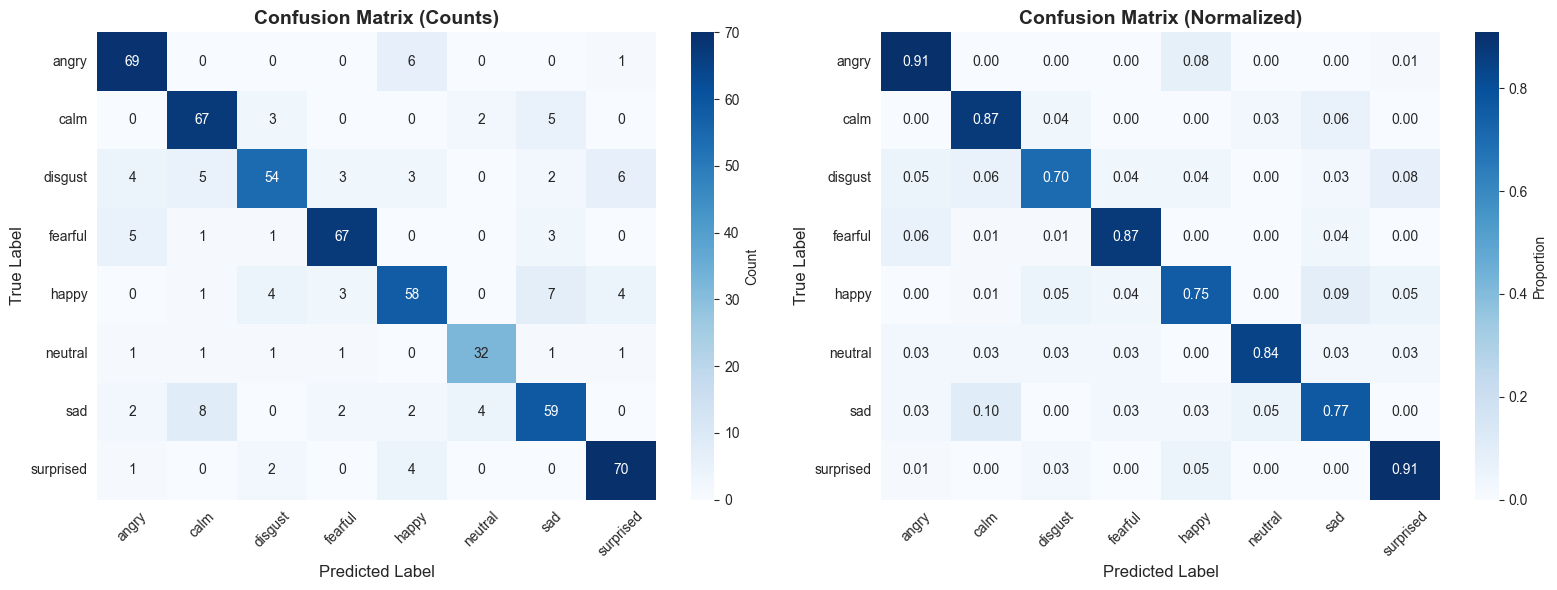

✓ Confusion matrix saved to ../results/confusion_matrix.png


<Figure size 1200x600 with 0 Axes>

In [ ]:

cm = confusion_matrix(y_test, y_pred_test)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].tick_params(axis='y', rotation=0)

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], cbar_kws={'label': 'Proportion'})
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()


results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)
plt.savefig(results_dir / 'confusion_matrix.png', dpi=300, bbox_inches='tight')
print("✓ Confusion matrix saved to ../results/confusion_matrix.png")


### Feature Importance (for tree-based models)


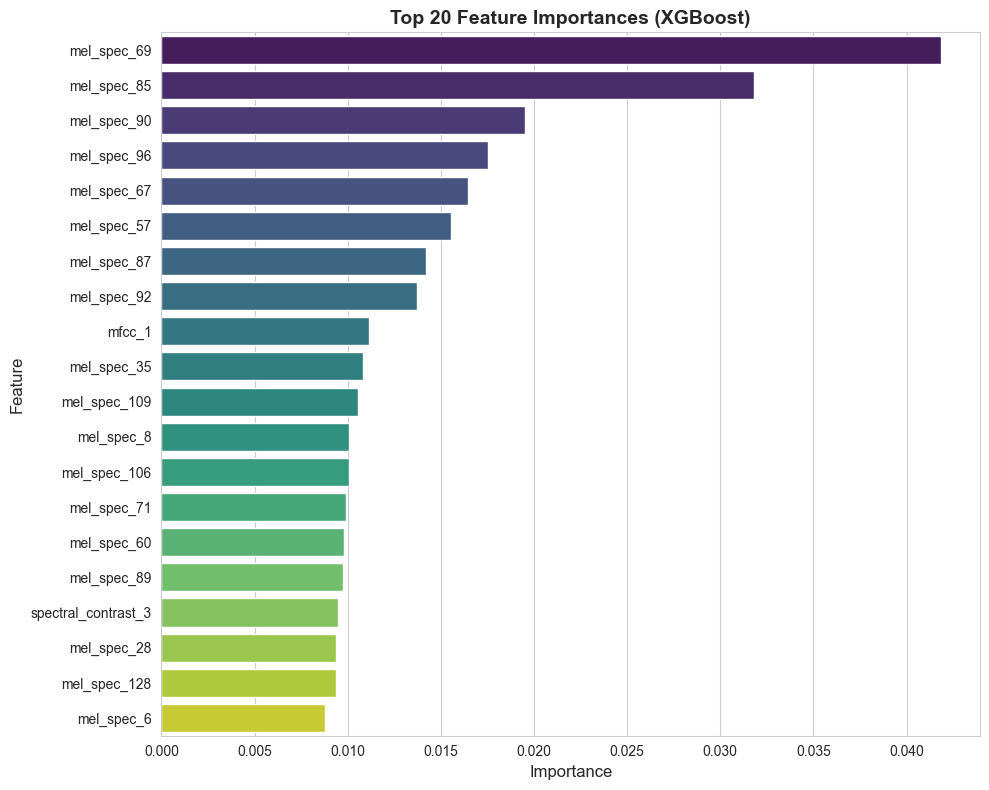

✓ Feature importance plot saved to ../results/feature_importance.png


<Figure size 1200x600 with 0 Axes>

In [ ]:

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    feature_importance_df = pd.DataFrame({
        'feature': sorted(feature_cols),
        'importance': importances
    }).sort_values('importance', ascending=False)
    
    
    top_features = feature_importance_df.head(20)
    
    plt.figure(figsize=(10, 8))
    sns.barplot(data=top_features, y='feature', x='importance', palette='viridis')
    plt.title(f'Top 20 Feature Importances ({best_name})', fontsize=14, fontweight='bold')
    plt.xlabel('Importance', fontsize=12)
    plt.ylabel('Feature', fontsize=12)
    plt.tight_layout()
    plt.show()
    
    
    plt.savefig(results_dir / 'feature_importance.png', dpi=300, bbox_inches='tight')
    print("✓ Feature importance plot saved to ../results/feature_importance.png")
else:
    print(f"Model {best_name} does not support feature importance visualization.")


## 6. Prediction 




In [ ]:


def predict_emotion(audio_path, model, label_encoder, scaler, feature_names):
    """Predict emotion from an audio file."""
    
    features = extract_all_features(audio_path)
    
    if features is None:
        return None
    
    
    feature_vector = np.array([features.get(feat, 0.0) for feat in feature_names])
    
    
    if np.isnan(feature_vector).any():
        feature_vector = np.nan_to_num(feature_vector, nan=0.0)
    
    
    feature_vector = feature_vector.reshape(1, -1)
    
    
    feature_vector_scaled = scaler.transform(feature_vector)
    
    
    prediction_encoded = model.predict(feature_vector_scaled)[0]
    prediction = label_encoder.inverse_transform([prediction_encoded])[0]
    
    
    if hasattr(model, 'predict_proba'):
        probabilities = model.predict_proba(feature_vector_scaled)[0]
        prob_dict = {
            label_encoder.inverse_transform([i])[0]: prob 
            for i, prob in enumerate(probabilities)
        }
    else:
        prob_dict = None
    
    return {
        'audio_path': str(audio_path),
        'predicted_emotion': prediction,
        'probabilities': prob_dict
    }

print("✓ Prediction function defined!")


✓ Prediction function defined!


### Make a Prediction



In [ ]:

audio_path = Path("../data/ravdess/Actor_01/03-01-01-01-01-01-01.wav")


with open(models_dir / 'feature_names.pkl', 'rb') as f:
    feature_names = pickle.load(f)


result = preditct_emotion(audio_path, best_model, label_encoder, scaler, feature_names)

if result:
    print("="*60)
    print("EMOTION PREDICTION")
    print("="*60)
    print(f"Audio File: {result['audio_path']}")
    print(f"Predicted Emotion: {result['predicted_emotion'].upper()}")
    
    if result['probabilities']:
        print("\nPrediction Probabilities:")
        sorted_probs = sorted(
            result['probabilities'].items(), 
            key=lambda x: x[1], 
            reverse=True
        )
        for emotion, prob in sorted_probs:
            print(f"  {emotion:15s}: {prob:.4f} ({prob*100:.2f}%)")
    print("="*60)
else:
    print("Error: Could not process audio file.")


EMOTION PREDICTION
Audio File: ..\data\ravdess\Actor_01\03-01-01-01-01-01-01.wav
Predicted Emotion: NEUTRAL

Prediction Probabilities:
  neutral        : 0.9726 (97.26%)
  sad            : 0.0082 (0.82%)
  disgust        : 0.0049 (0.49%)
  fearful        : 0.0047 (0.47%)
  calm           : 0.0032 (0.32%)
  surprised      : 0.0032 (0.32%)
  angry          : 0.0018 (0.18%)
  happy          : 0.0014 (0.14%)


## 7. Data Exploration 




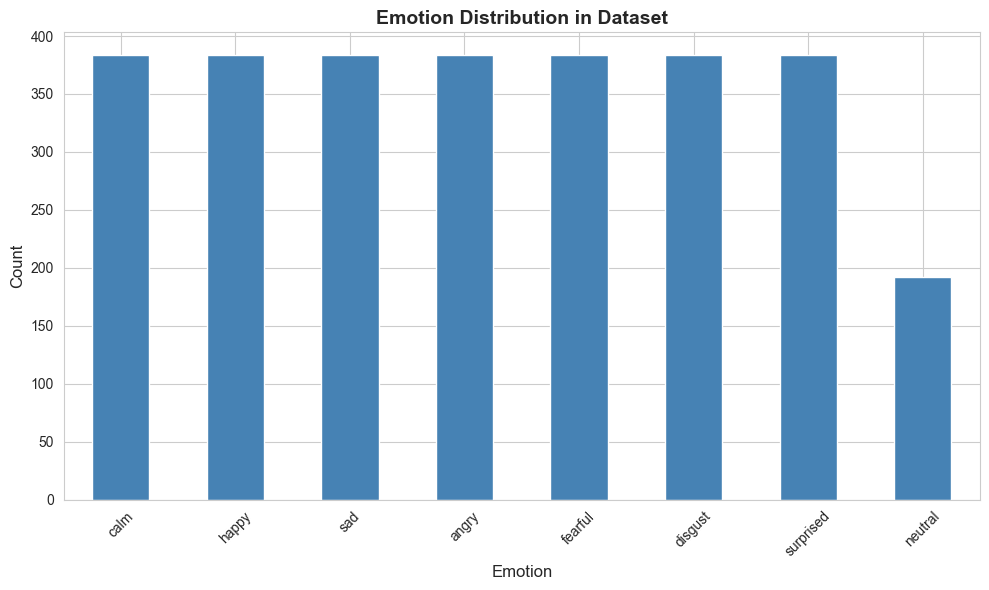


Emotion Distribution:
emotion
calm         384
happy        384
sad          384
angry        384
fearful      384
disgust      384
surprised    384
neutral      192
Name: count, dtype: int64


In [ ]:

emotion_counts = df_features['emotion'].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
emotion_counts.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Emotion Distribution in Dataset', fontsize=14, fontweight='bold')
ax.set_xlabel('Emotion', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print("\nEmotion Distribution:")
print(emotion_counts)


In [ ]:

print(f"Total features: {len(feature_cols)}")
print(f"\nFeature Statistics (sample of first 10 features):")
print(df_features[feature_cols[:10]].describe())


Total features: 191

Feature Statistics (sample of first 10 features):
          chroma_1    chroma_10    chroma_11    chroma_12     chroma_2  \
count  2880.000000  2880.000000  2880.000000  2880.000000  2880.000000   
mean      0.461253     0.484690     0.489117     0.477123     0.461983   
std       0.082034     0.079556     0.079868     0.077896     0.090297   
min       0.154924     0.245012     0.237909     0.256060     0.158028   
25%       0.404146     0.429985     0.436338     0.423210     0.397642   
50%       0.462734     0.484691     0.490880     0.479770     0.463484   
75%       0.521135     0.541367     0.544814     0.531690     0.529474   
max       0.683413     0.744964     0.724036     0.678723     0.720075   

          chroma_3     chroma_4     chroma_5     chroma_6     chroma_7  
count  2880.000000  2880.000000  2880.000000  2880.000000  2880.000000  
mean      0.456907     0.473570     0.478293     0.484058     0.471799  
std       0.091623     0.094697     0.10031

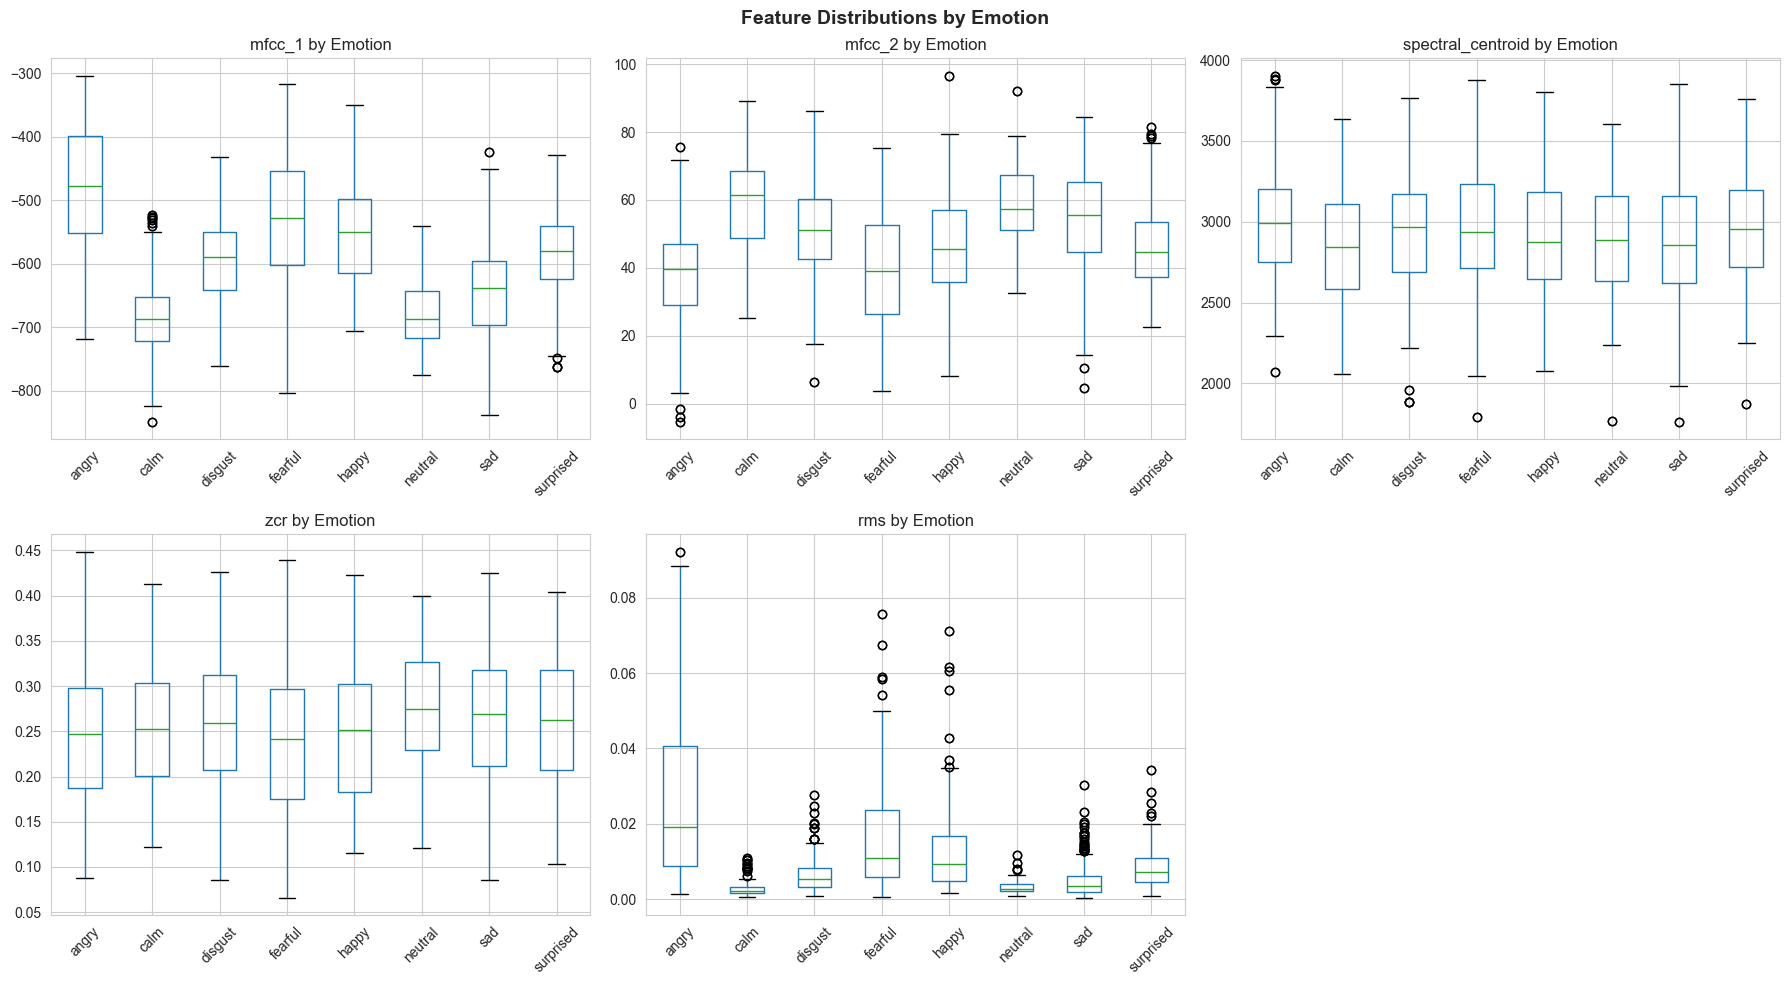

In [ ]:

key_features = ['mf---cc_1', 'mfcc_2', 'spectral_centroid', 'zcr', 'rms']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(key_features):
    if feature in df_features.columns:
        df_features.boxplot(column=feature, by='emotion', ax=axes[i])
        axes[i].set_title(f'{feature} by Emotion')
        axes[i].set_xlabel('')
        axes[i].tick_params(axis='x', rotation=45)


fig.delaxes(axes[-1])

plt.suptitle('Feature Distributions by Emotion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
